# Analysis Report

This notebook reads summary JSON files written by each analysis notebook and renders a combined report.
It does not rerun any analysis — it only reads pre-computed results.

**To use:** run all cells top to bottom after completing the analysis notebooks.

**Export to HTML (no code cells):**
```bash
jupyter nbconvert --to html --no-input report.ipynb --output report.html
```

In [1]:
import json
import os
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, HTML, Image
from datetime import datetime

# ── Configuration ─────────────────────────────────────────────────────────────
# Set SAMPLE_ID to match the analysis notebook
SAMPLE_ID   = "pbmc3k_cpu"
BASE_DIR    = f"/home/jovyan/work/analyses/{SAMPLE_ID}"
FIG_DIR     = f"{BASE_DIR}/figures"
SUMMARY_DIR = f"{BASE_DIR}/summaries"

print(f"Report for: {SAMPLE_ID}")
print(f"Generated:  {datetime.now().strftime('%Y-%m-%d %H:%M')}")

Report for: pbmc3k_cpu
Generated:  2026-10-24 14:02


In [2]:
# ── Load summaries ────────────────────────────────────────────────────────────
summaries = {}
summary_files = {
    "scrna"    : f"{SUMMARY_DIR}/scrna_summary.json",
    "velocity" : f"{SUMMARY_DIR}/velocity_summary.json",
    "spatial"  : f"{SUMMARY_DIR}/spatial_summary.json",
    "pseudo"   : f"{SUMMARY_DIR}/pseudo_summary.json",
}

for key, path in summary_files.items():
    if os.path.exists(path):
        with open(path) as f:
            summaries[key] = json.load(f)
        print(f"  Loaded: {key}")
    else:
        print(f"  Not found (skipping): {key}")

if not summaries:
    raise FileNotFoundError(f"No summary files found in {SUMMARY_DIR}")

  Loaded: scrna
  Not found (skipping): velocity
  Not found (skipping): spatial
  Not found (skipping): pseudo


---
## 1. Experiment metadata

In [3]:
if "scrna" in summaries:
    meta   = summaries["scrna"]["metadata"]
    params = summaries["scrna"]["params"]

    meta_df = pd.DataFrame([
        {"Field": "Sample ID",    "Value": meta["sample_id"]},
        {"Field": "Date",         "Value": meta["date"]},
        {"Field": "Author",       "Value": meta["author"]},
        {"Field": "Kernel",       "Value": meta["kernel"]},
        {"Field": "Notebook",     "Value": meta["notebook"]},
        {"Field": "Random seed",  "Value": params["seed"]},
        {"Field": "MAD nmads",    "Value": params["mad_nmads"]},
        {"Field": "n HVGs",       "Value": params["n_hvgs"]},
        {"Field": "n PCs used",   "Value": params["n_pcs_use"]},
        {"Field": "n neighbours", "Value": params["n_neighbours"]},
        {"Field": "Leiden final", "Value": params["leiden_final"]},
    ])
    display(HTML(meta_df.to_html(index=False, border=0, justify="left")))

Field,Value
Sample ID,pbmc3k_cpu
Date,2026-10-24
Author,CH
Kernel,env_core
Notebook,01_scrna_analysis.ipynb
Random seed,42
MAD nmads,5
n HVGs,2000
n PCs used,30
n neighbours,30


---
## 2. Primary QC

── QC thresholds ──────────────────────────────────────


Threshold,Value
min_genes,200.00
max_genes,1474.50
min_counts,500.00
max_counts,4692.00
max_pct_mt,4.73
max_pct_hb,0.00



── Cell count tracking ─────────────────────────────────


step,n_cells,n_genes,cells_removed,notes
Raw,2700,32738,0,Input count matrix
Post gene filter,2700,13714,0,min_cells=3
Filter: low genes,2700,13714,0,n_genes_by_counts >= 200.0
Filter: high genes (putative doublets),2611,13714,89,n_genes_by_counts <= 1474.5
Filter: low counts,2611,13714,0,total_counts >= 500.0
Filter: high counts (putative doublets),2597,13714,14,total_counts <= 4692.0
Filter: high mt% (dying cells),2522,13714,75,pct_counts_mt <= 4.7
Filter: high hb% (RBC contamination),2497,13714,25,pct_counts_hb <= 0.0
Post doublet detection,2497,13714,0,SOLO flagged 121 (4.8%) — not yet removed



── Summary ─────────────────────────────────────────────
  Cells (raw → final): 2700 → 2497
  Genes retained:      13714
  HVGs selected:       2000


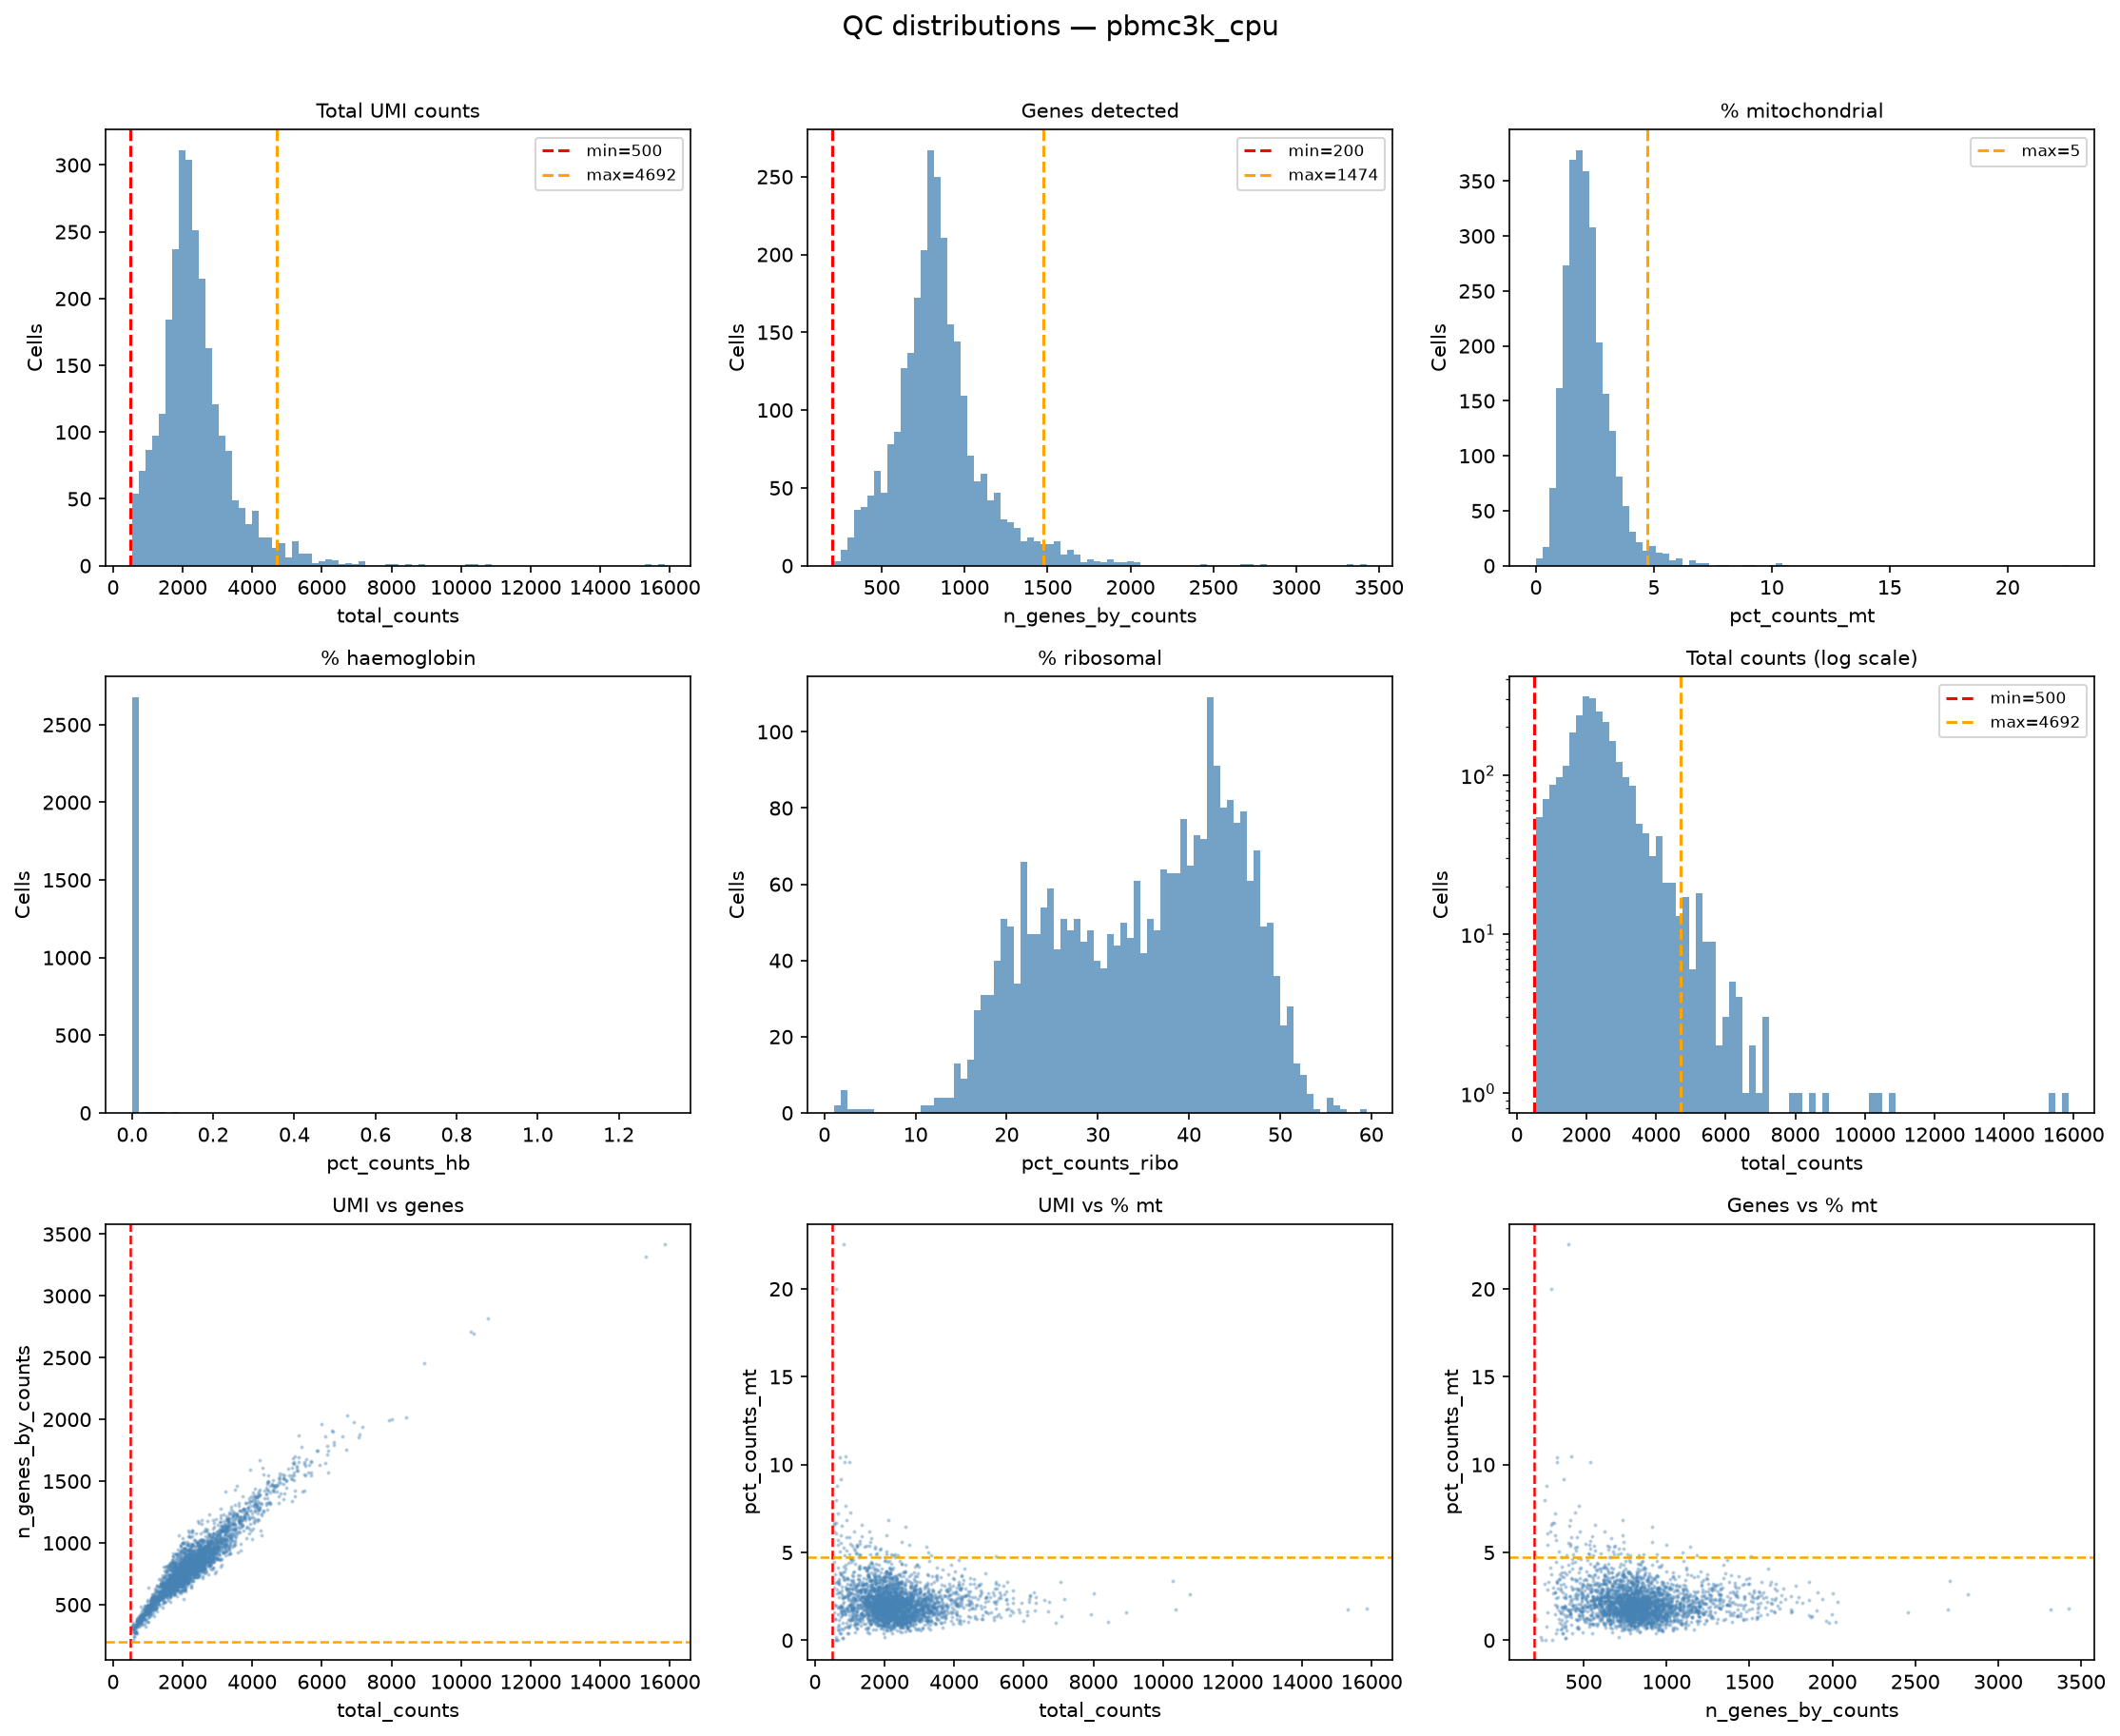

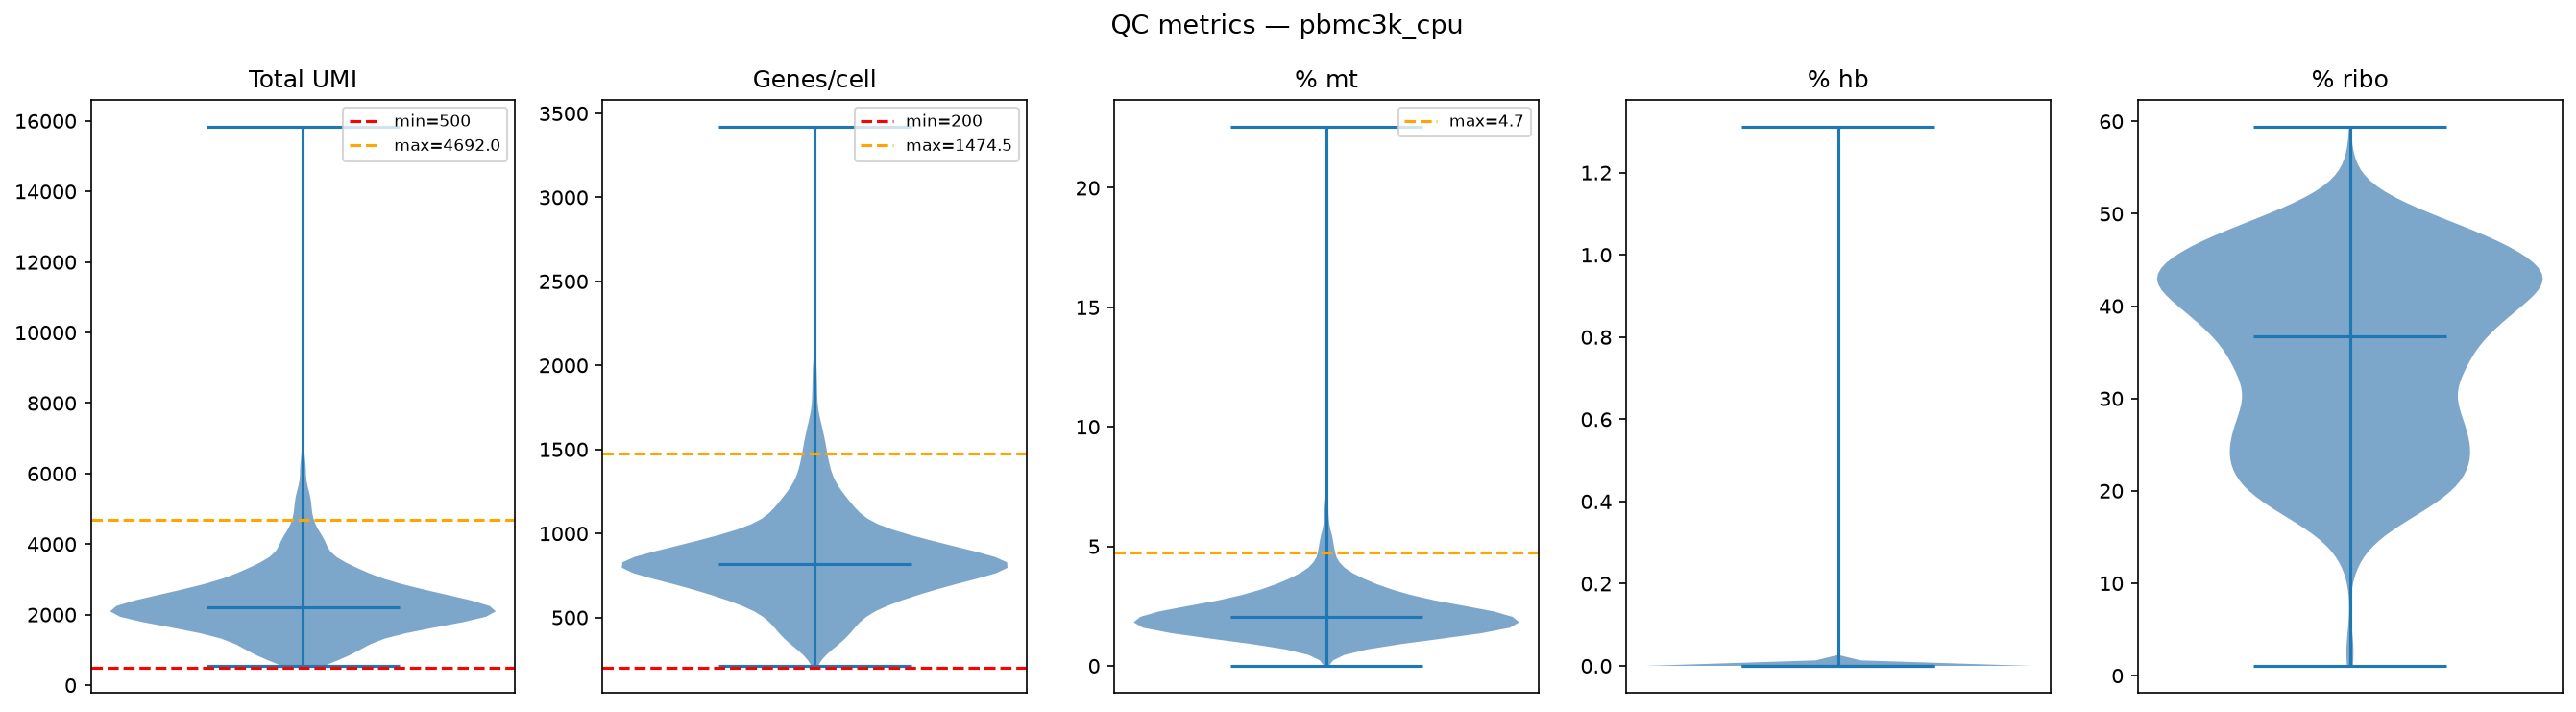

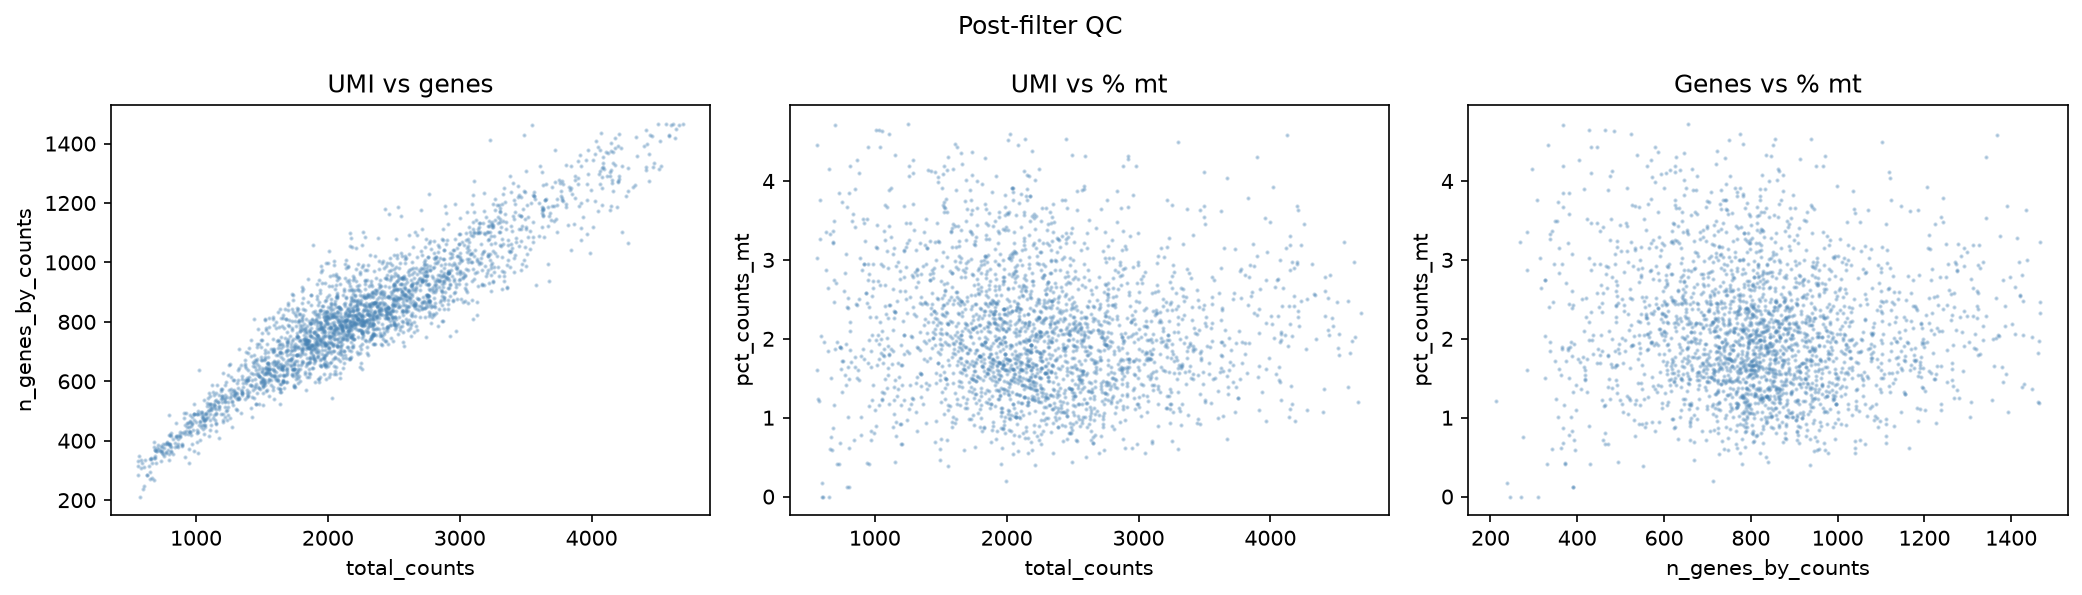

In [4]:
def show_fig(filename, title=None):
    path = f"{FIG_DIR}/{filename}"
    if os.path.exists(path):
        if title:
            display(HTML(f"<h4>{title}</h4>"))
        display(Image(path))
    else:
        print(f"Figure not found: {filename}")

if "scrna" in summaries:
    qc = summaries["scrna"]["qc"]

    print("── QC thresholds ──────────────────────────────────────")
    thresh_df = pd.DataFrame(
        [{"Threshold": k, "Value": v} for k, v in qc["thresholds"].items()]
    )
    display(HTML(thresh_df.to_html(index=False, border=0, justify="left")))

    print("\n── Cell count tracking ─────────────────────────────────")
    counts_df = pd.DataFrame(qc["cell_counts_table"])
    display(HTML(counts_df.to_html(index=False, border=0, justify="left")))

    print(f"\n── Summary ─────────────────────────────────────────────")
    print(f"  Cells (raw → final): {qc['n_cells_raw']} → {qc['n_cells_final']}")
    print(f"  Genes retained:      {qc['n_genes_final']}")
    print(f"  HVGs selected:       {qc['n_hvgs']}")

show_fig("01_qc_distributions.png", "QC metric distributions")
show_fig("02_qc_violins.png",       "QC violin plots")
show_fig("03_qc_postfilter.png",    "Post-filter QC")

---
## 3. Doublet detection

Method:             scrublet
Predicted doublets: 121 (4.8%)


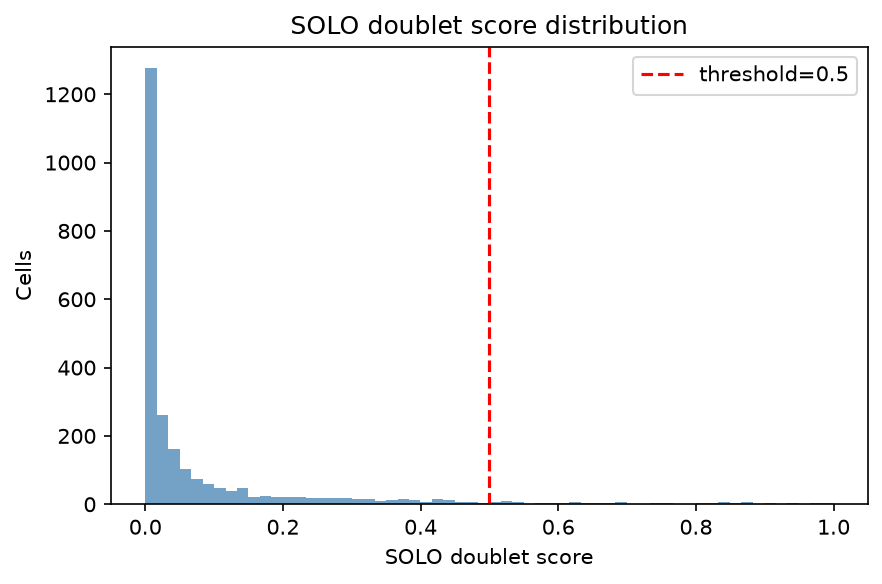

In [5]:
if "scrna" in summaries:
    db = summaries["scrna"]["doublets"]
    print(f"Method:             {db['method']}")
    print(f"Predicted doublets: {db['n_predicted']} ({db['pct_predicted']:.1f}%)")

show_fig("04_solo_doublets.png", "SOLO doublet score distribution")

---
## 4. Clustering

Parameter,Value
Method,leiden
Resolutions tested,"[0.3, 0.5, 0.8, 1.0, 1.5]"
Final resolution,0.5
Clusters,5
PCs used,30
Neighbours,30


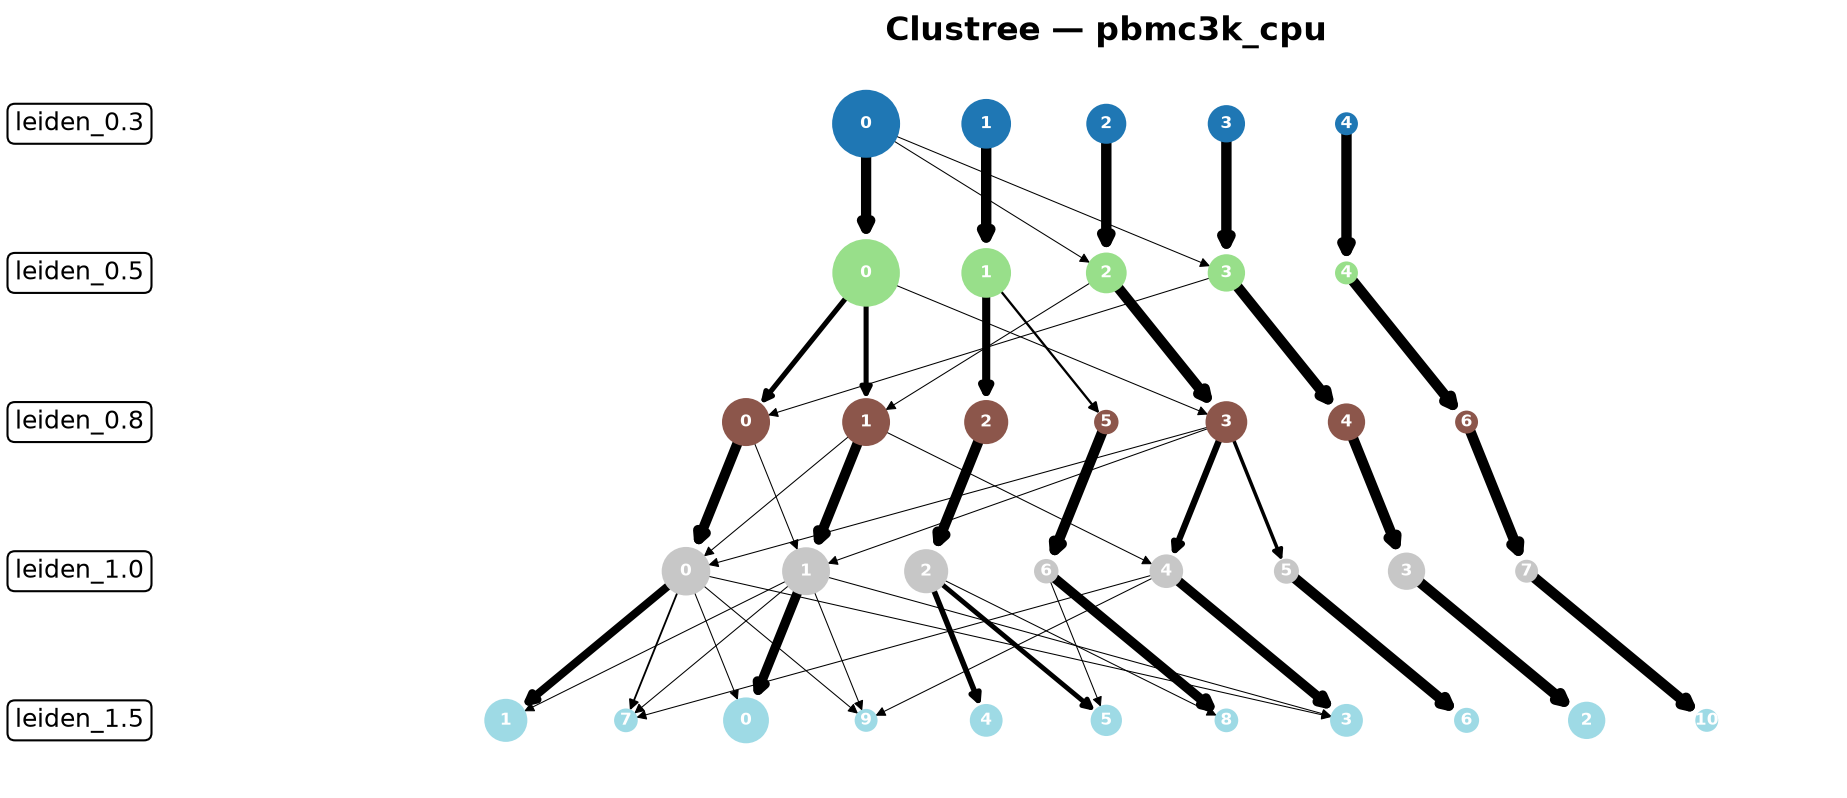

In [6]:
if "scrna" in summaries:
    cl = summaries["scrna"]["clustering"]
    cl_df = pd.DataFrame([
        {"Parameter": "Method",             "Value": cl["method"]},
        {"Parameter": "Resolutions tested", "Value": str(cl["resolutions_tested"])},
        {"Parameter": "Final resolution",   "Value": cl["resolution_final"]},
        {"Parameter": "Clusters",           "Value": cl["n_clusters"]},
        {"Parameter": "PCs used",           "Value": cl["n_pcs_used"]},
        {"Parameter": "Neighbours",         "Value": cl["n_neighbours"]},
    ])
    display(HTML(cl_df.to_html(index=False, border=0, justify="left")))

show_fig("08_clustree.png", "Clustree — resolution stability")

---
## 5. Cell type annotation

Method:            celltypist
Model:             Immune_All_Low.pkl
Median confidence: 0.927


Cell type,n cells,%
Tcm/Naive helper T cells,1146,45.9
Classical monocytes,606,24.3
CD16+ NK cells,400,16.0
B cells,333,13.3
Megakaryocytes/platelets,12,0.5


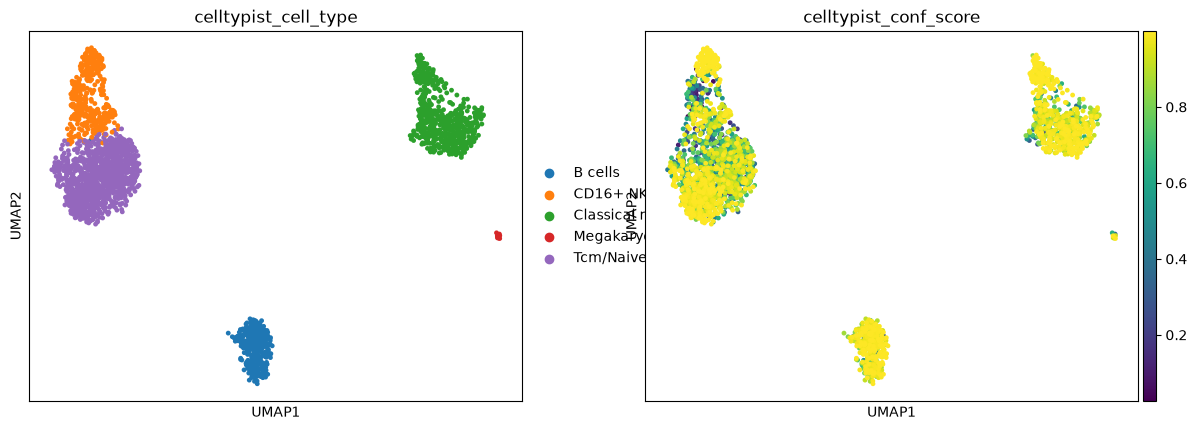

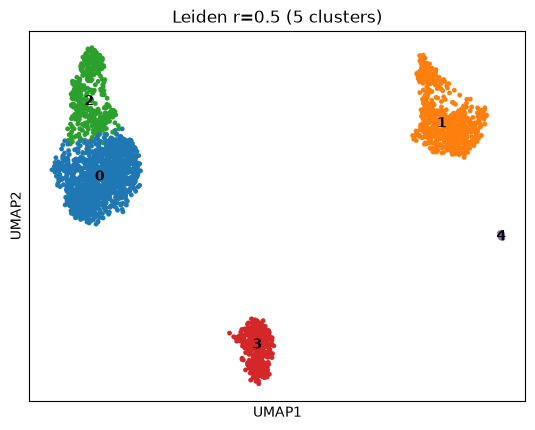

In [7]:
if "scrna" in summaries:
    ann = summaries["scrna"]["annotation"]
    print(f"Method:            {ann['method']}")
    print(f"Model:             {ann['model']}")
    print(f"Median confidence: {ann['median_conf_score']}")

    if ann["cell_type_counts"]:
        ct_df = pd.DataFrame(
            [{"Cell type": k, "n cells": v}
             for k, v in sorted(ann["cell_type_counts"].items(), key=lambda x: -x[1])]
        )
        ct_df["%"] = (ct_df["n cells"] / ct_df["n cells"].sum() * 100).round(1)
        display(HTML(ct_df.to_html(index=False, border=0, justify="left")))

# Show UMAP and celltypist figures
for fname in sorted(os.listdir(FIG_DIR)):
    if "celltypist" in fname or "umap_final" in fname:
        show_fig(fname)

---
## 6. Velocity (if run)

In [8]:
if "velocity" in summaries:
    vel = summaries["velocity"]
    print(json.dumps(vel, indent=2, default=str))
else:
    print("No velocity summary found — run 02_velocity_analysis.ipynb first.")

No velocity summary found — run 02_velocity_analysis.ipynb first.


---
## 7. Pathway analysis (if run)

In [9]:
if "pseudo" in summaries:
    ps = summaries["pseudo"]
    print(json.dumps(ps, indent=2, default=str))
else:
    print("No pseudobulk summary found — run 05_pathway_analysis.ipynb first.")

No pseudobulk summary found — run 05_pathway_analysis.ipynb first.


---
## 8. Export report

Run the cell below to export as HTML without code cells.
The output file lands in the sample analysis directory.

In [10]:
import subprocess

notebook_path = "/home/jovyan/work/notebooks/report/report.ipynb"
output_path   = f"{BASE_DIR}/{SAMPLE_ID}_report_{datetime.now().strftime('%Y%m%d')}.html"

result = subprocess.run(
    [
        "jupyter", "nbconvert",
        "--to", "html",
        "--no-input",
        # remove --execute
        notebook_path,
        "--output", output_path
    ],
    capture_output=True, text=True
)

if result.returncode == 0:
    print(f"Report exported: {output_path}")
else:
    print("Export failed:")
    print(result.stderr)

Export failed:
[NbConvertApp] Converting notebook /home/jovyan/work/notebooks/report/report.ipynb to html
/opt/conda/lib/python3.12/site-packages/nbformat/validator.py:434: MissingIDFieldWarning: Cell is missing an id field, this will become a hard error in future nbformat versions. You may want to use `normalize()` on your notebooks before validations (available since nbformat 5.1.4). Previous versions of nbformat are fixing this issue transparently, and will stop doing so in the future.
  _validate(nbdict, ref, version, version_minor, relax_add_props)
[IPKernelApp] WARNING | Kernel is running over TCP without encryption. All communication (including code and outputs) is sent in plain text and is susceptible to eavesdropping. Use IPC transport or launch with kernel manager-provisioned CurveZMQ keys to enable transport encryption.
Traceback (most recent call last):
  File "/opt/conda/bin/jupyter-nbconvert", line 10, in <module>
    sys.exit(main())
             ^^^^^^
  File "/opt/cond